# 고유값·고유벡터와 최소제곱

작은 예제로 원리 확인 → 코드 실행 → 한 조건 변경 → 결과 해석

위에서 아래로 실행. 일반 CPU로 진행 가능. 날짜·평가 운영은 학기 운영안내에서 확인

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
np.set_printoptions(precision=5, suppress=True)

## 방향이 유지되는 벡터

A=[[2,1],[1,2]]의 고유값·고유벡터를 구하시오. A v=λv를 수치로 확인하고, 임의의 벡터와 차이를 설명하시오.

In [2]:
A = np.array([[2.,1.],[1.,2.]])
values, vectors = np.linalg.eigh(A)
print(values); print(vectors)
print('잔차:', A@vectors-vectors*values)
assert np.allclose(A@vectors,vectors*values)
assert np.allclose(vectors.T@vectors,np.eye(2))
N = np.array([[2.,2.],[1.,3.]])
lam,V = np.linalg.eig(N)
print('비대칭 행렬 복원:', V@np.diag(lam)@np.linalg.inv(V))

[1. 3.]
[[-0.70711  0.70711]
 [ 0.70711  0.70711]]
잔차: [[0. 0.]
 [0. 0.]]
비대칭 행렬 복원: [[2. 2.]
 [1. 3.]]


## 역행렬이 없는 경우

A=[[-1,1],[0,1],[0,1]], b=[0,1,3]의 최소제곱해를 구하시오. 잔차와 A의 각 열벡터가 수직인지 확인하시오.

해: [2. 2.] 잔차: [ 0. -1.  1.] A.T @ 잔차: [-0.  0.]


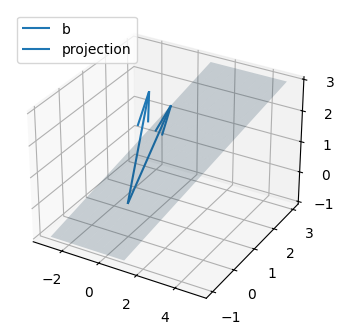

In [3]:
A = np.array([[-1.,1.],[0.,1.],[0.,1.]])
b = np.array([0.,1.,3.])
x = np.linalg.pinv(A)@b
residual = b-A@x
print('해:',x,'잔차:',residual,'A.T @ 잔차:',A.T@residual)
assert np.allclose(x,[2.,2.])
assert np.allclose(A.T@residual,0)
fig = plt.figure(figsize=(5,4));ax = fig.add_subplot(projection='3d')
u,t = np.meshgrid(np.linspace(-2,2,10),np.linspace(-1,3,10))
plane = A[:,0,None,None]*u + A[:,1,None,None]*t
ax.plot_surface(*plane,alpha=.2)
for z,label in [(b,'b'),(A@x,'projection')]:
    ax.quiver(0,0,0,*z,label=label)
ax.legend();plt.show()

## 안정적인 계산

`inv(A.T@A)@A.T@b`와 `lstsq`를 비교하시오. 두 열이 거의 같은 행렬에서는 어느 방법이 더 안정적인지 조사하고 이유를 설명하시오.

In [4]:
x2 = np.linalg.lstsq(A,b,rcond=None)[0]
assert np.allclose(x,x2)
print('열이 완전히 중복된 경우에도 계산:', np.linalg.pinv(np.column_stack([A[:,1],A[:,1]]))@b)

열이 완전히 중복된 경우에도 계산: [0.66667 0.66667]
